In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
import pandas as pd
import numpy as np
import sqlite3


df = pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
conn = sqlite3.connect('churn.db')   
df.to_sql('raw_customers', conn, if_exists='replace', index=False)

pd.read_sql("SELECT COUNT(*) AS count FROM raw_customers", conn)  

,count
0,7043


In [5]:
conn.executescript("""
DROP TABLE IF EXISTS customers;
CREATE TABLE customers AS
SELECT customerID, gender, SeniorCitizen, Partner, Dependents, tenure, Churn
FROM raw_customers;
""")

In [6]:
conn.executescript("""
DROP TABLE IF EXISTS services;
create table services AS 
select customerID, PhoneService, MultipleLines, InternetService, OnlineSecurity, DeviceProtection,TechSupport,StreamingTV,StreamingMovies
from raw_customers;
""")

In [7]:
conn.executescript("""
drop table if exists billing;
create table billing as 
SELECT customerID, Contract, PaperlessBilling, PaymentMethod,
       MonthlyCharges, TotalCharges
FROM raw_customers;
""")

In [8]:
pd.read_sql("""
SELECT c.customerID, c.Churn, b.Contract, s.InternetService
FROM customers c
JOIN billing b ON c.customerID = b.customerID
JOIN services s ON c.customerID = s.customerID
LIMIT 5
""", conn)

,customerID,Churn,Contract,InternetService
0,7590-VHVEG,No,Month-to-month,DSL
1,5575-GNVDE,No,One year,DSL
2,3668-QPYBK,Yes,Month-to-month,DSL
3,7795-CFOCW,No,One year,DSL
4,9237-HQITU,Yes,Month-to-month,Fiber optic


In [9]:
pd.read_sql("""
SELECT s.InternetService,
       COUNT(*) AS customers,
       SUM(c.Churn = 'Yes') AS churned,
       ROUND(AVG(c.Churn = 'Yes') * 100, 1) AS churn_rate_pct
FROM customers c
JOIN services s ON c.customerID = s.customerID
GROUP BY s.InternetService
ORDER BY churn_rate_pct DESC
""", conn)

,InternetService,customers,churned,churn_rate_pct
0,Fiber optic,3096,1297,41.9
1,DSL,2421,459,19.0
2,No,1526,113,7.4


In [10]:
pd.read_sql("""
select count(*) as customers , b.PaymentMethod , sum(c.churn="Yes") as churned  , round(avg(c.churn="Yes")*100,1) as churn_rate
from customers c join billing b on c.customerID = b.customerID
group by b.PaymentMethod
""",conn)

,customers,PaymentMethod,churned,churn_rate
0,1544,Bank transfer (automatic),258,16.7
1,1522,Credit card (automatic),232,15.2
2,2365,Electronic check,1071,45.3
3,1612,Mailed check,308,19.1


In [11]:
pd.read_sql("""
select count(*) as customers , round(SUM(b.MonthlyCharges),2) as revenue_loss
from customers c join billing b on c.customerID = b.customerID
where c.churn="Yes"
""",conn)

,customers,revenue_loss
0,1869,139130.85


**Churned customers represent about 139K in lost monthly recurring revenue, roughly 2.1M per year, which sets the budget ceiling for any retention program.”**

In [12]:
pd.read_sql("""
SELECT c.Churn,
       COUNT(*) AS customers,
       ROUND(AVG(b.MonthlyCharges), 2) AS avg_monthly_charge,
       ROUND(SUM(b.MonthlyCharges), 2) AS total_monthly_revenue
FROM customers c
JOIN billing b ON c.customerID = b.customerID
GROUP BY c.Churn
""", conn)

,Churn,customers,avg_monthly_charge,total_monthly_revenue
0,No,5174,61.27,316985.75
1,Yes,1869,74.44,139130.85


In [13]:
df = pd.read_sql("""
SELECT *
FROM customers
JOIN services USING (customerID)
JOIN billing USING (customerID)
""", conn)

df.shape

(7043, 20)

In [14]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
Churn                0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
dtype: int64

In [15]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
Churn               0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

In [16]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

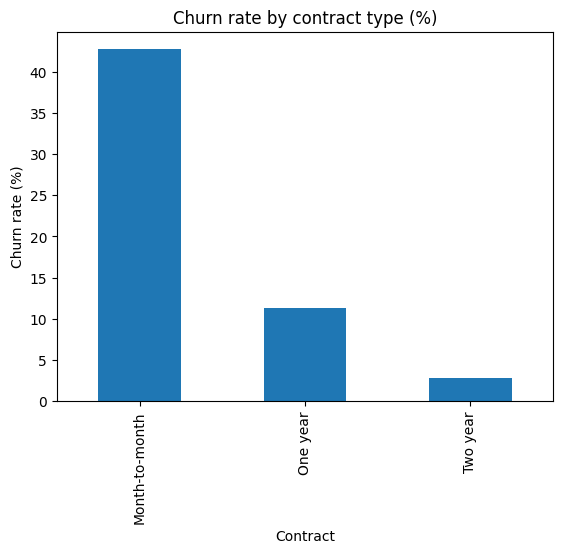

In [17]:
import matplotlib.pyplot as plt

churn_by_contract = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
churn_by_contract.plot(kind='bar', title='Churn rate by contract type (%)')
plt.ylabel('Churn rate (%)')
plt.show()

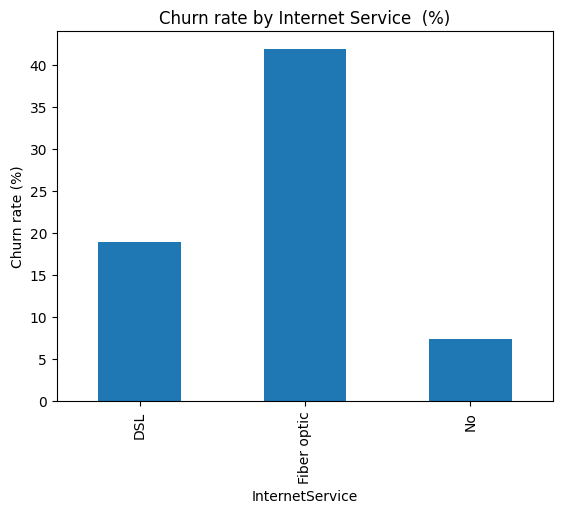

In [18]:
import matplotlib.pyplot as plt

churn_by_contract = df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
churn_by_contract.plot(kind='bar', title='Churn rate by Internet Service  (%)')
plt.ylabel('Churn rate (%)')
plt.show()

In [20]:
y = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns=['customerID', 'Churn'])

In [22]:
X = pd.get_dummies(X, drop_first=True)
X.shape

(7043, 28)

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train.shape, X_test.shape

((5634, 28), (1409, 28))

In [27]:
from sklearn.preprocessing import StandardScaler

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [30]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [32]:
from sklearn.metrics import classification_report
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [34]:
pred_03 = (proba >= 0.3).astype(int)
print(classification_report(y_test, pred_03))

              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [35]:
from sklearn.metrics import precision_score, recall_score

for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (proba >= t).astype(int)
    print(t, 
          "precision:", round(precision_score(y_test, p), 2),
          "recall:", round(recall_score(y_test, p), 2),
          "flagged:", p.sum())

0.2 precision: 0.47 recall: 0.86 flagged: 684
0.3 precision: 0.52 recall: 0.76 flagged: 542
0.4 precision: 0.57 recall: 0.67 flagged: 440
0.5 precision: 0.66 recall: 0.56 flagged: 320
0.6 precision: 0.71 recall: 0.39 flagged: 207


In [36]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

rf_proba = rf.predict_proba(X_test)[:, 1]
rf_pred = (rf_proba >= 0.5).astype(int)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [37]:
from sklearn.metrics import roc_auc_score

print("Logistic regression AUC:", round(roc_auc_score(y_test, proba), 3))
print("Random forest AUC:      ", round(roc_auc_score(y_test, rf_proba), 3))

Logistic regression AUC: 0.842
Random forest AUC:       0.826


In [39]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train, y_train)

xgb_proba = xgb.predict_proba(X_test)[:, 1]

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_proba = rf.predict_proba(X_test)[:, 1]

print("Logistic regression AUC:", round(roc_auc_score(y_test, proba), 3))
print("Random forest AUC:      ", round(roc_auc_score(y_test, rf_proba), 3))
print("XGBoost AUC:            ", round(roc_auc_score(y_test, xgb_proba), 3))

Logistic regression AUC: 0.842
Random forest AUC:       0.826
XGBoost AUC:             0.844


In [41]:
import shap

X_test_f = X_test.astype(float)  

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test_f)

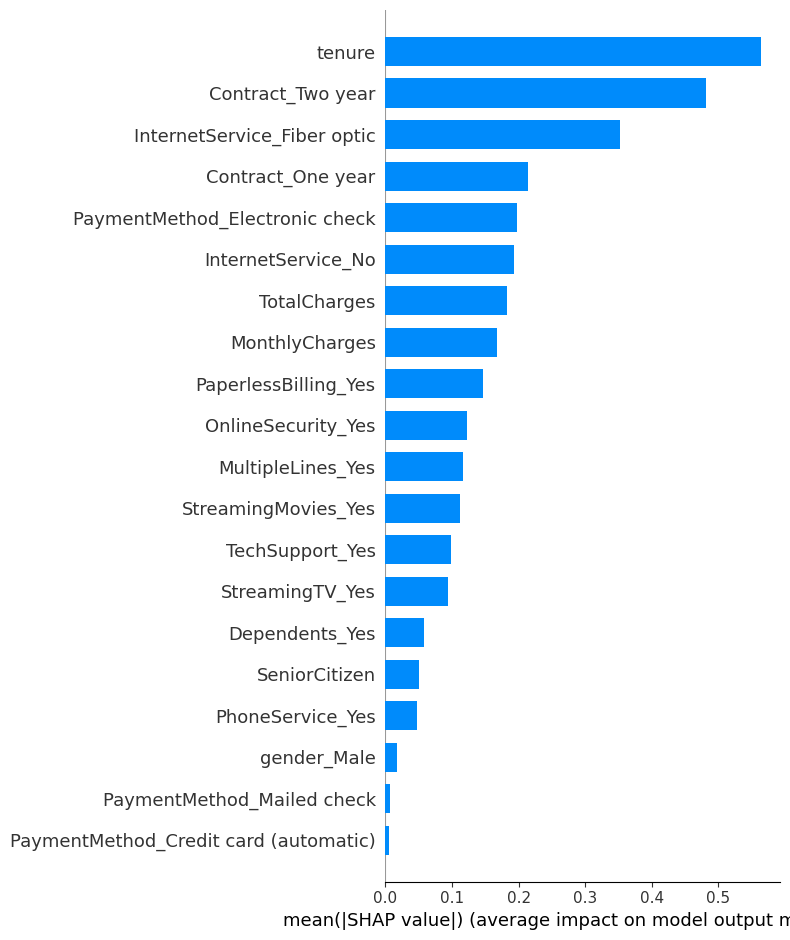

In [43]:
shap.summary_plot(shap_values, X_test_f, plot_type="bar")

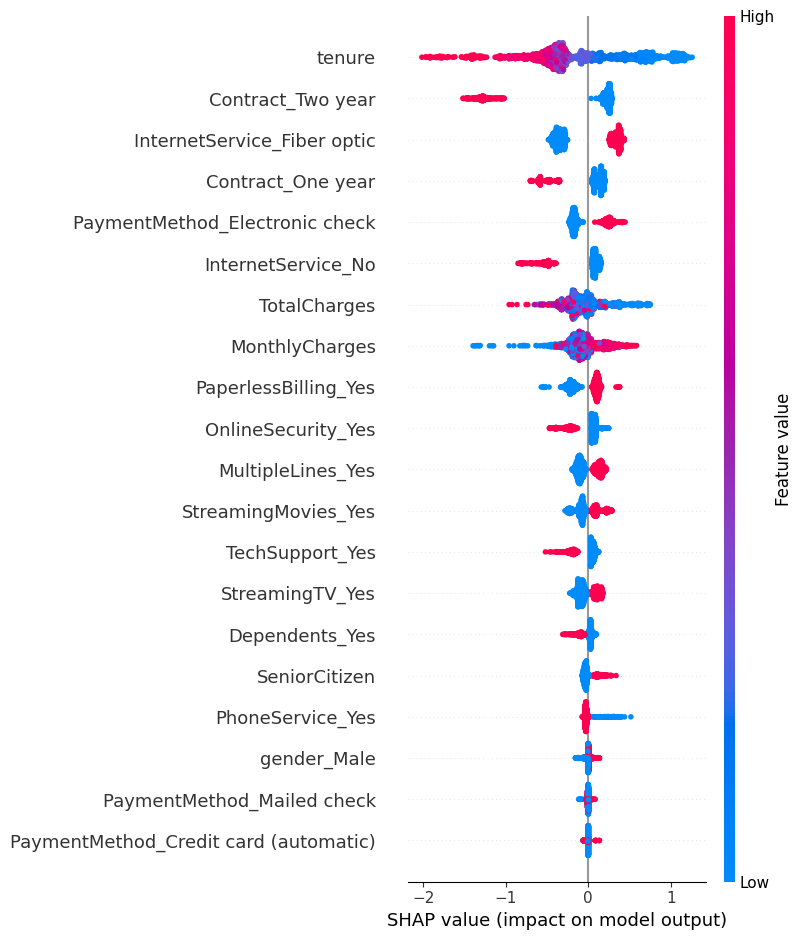

In [44]:
shap.summary_plot(shap_values, X_test_f)

In [54]:
offer_cost = 20      # cost of one retention offer
customer_value = 890     # yearly revenue of one churner (about 74 x 12)
success_rate = 0.30      # share of flagged churners the offer actually saves

In [55]:
import numpy as np

results = []
for t in np.arange(0.05, 0.95, 0.05):
    flagged = xgb_proba >= t
    tp = (flagged & (y_test == 1)).sum()   
    fp = (flagged & (y_test == 0)).sum()    

    saved_value = tp * success_rate * customer_value
    total_cost = (tp + fp) * offer_cost
    profit = saved_value - total_cost

    results.append((round(t, 2), flagged.sum(), tp, fp, round(profit)))

cost_df = pd.DataFrame(results, columns=['threshold', 'flagged', 'tp', 'fp', 'profit'])
cost_df

,threshold,flagged,tp,fp,profit
0,0.05,1019,366,653,77342
1,0.10,864,350,514,76170
2,0.15,757,338,419,75106
3,0.20,678,319,359,71613
4,0.25,600,302,298,68634
5,0.30,553,287,266,65569
6,0.35,484,268,216,61876
7,0.40,420,250,170,58350
8,0.45,357,221,136,51867
9,0.50,295,194,101,45898


threshold        0.05
flagged       1019.00
tp             366.00
fp             653.00
profit       77342.00
Name: 0, dtype: float64


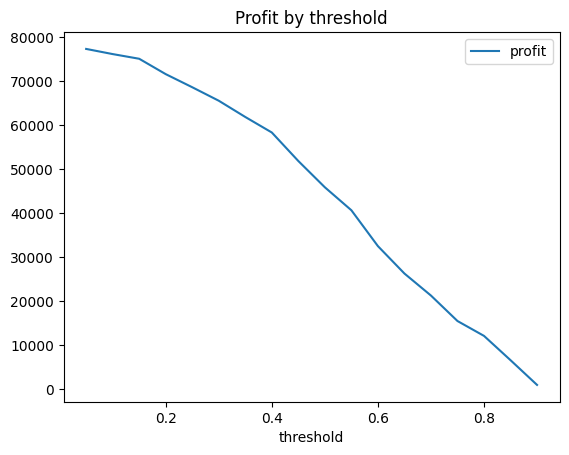

In [56]:
best = cost_df.loc[cost_df['profit'].idxmax()]
print(best)

cost_df.plot(x='threshold', y='profit', title='Profit by threshold')
plt.show()

In [57]:
def best_threshold(offer_cost, proba=xgb_proba, customer_value=890, success_rate=0.30):
    y = y_test.values
    best = None
    for t in np.arange(0.05, 0.95, 0.05):
        flagged = proba >= t
        tp = (flagged & (y == 1)).sum()
        fp = (flagged & (y == 0)).sum()
        profit = tp * success_rate * customer_value - (tp + fp) * offer_cost
        if best is None or profit > best[2]:
            best = (round(t, 2), int(flagged.sum()), round(profit))
    return best

In [58]:
def contact_everyone(offer_cost, customer_value=890, success_rate=0.30):
    y = y_test.values
    return round(y.sum() * success_rate * customer_value - len(y) * offer_cost)

In [59]:
rows = []
for cost in [20, 50, 100, 150, 200]:
    t, n, p = best_threshold(cost)
    rows.append((cost, t, n, p, contact_everyone(cost)))

sens = pd.DataFrame(rows, columns=['offer_cost', 'best_threshold', 'customers_flagged',
                                   'model_profit', 'contact_everyone_profit'])
sens

,offer_cost,best_threshold,customers_flagged,model_profit,contact_everyone_profit
0,20,0.05,1019,77342,71678
1,50,0.15,757,52396,29408
2,100,0.40,420,24750,-41042
3,150,0.55,249,8307,-111492
4,200,0.70,110,1496,-181942


In [60]:
import joblib
joblib.dump(xgb, 'xgb_model.pkl')
joblib.dump(list(X_train.columns), 'model_columns.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']